# ShapeFit templates: standard vs BRASS-like (`ShapeFitFastSpectrum2Template`)

`desilike` has two ways of applying the ShapeFit tilt

$$
S(k) = \exp\left[\frac{\Delta m}{a}\tanh\left(a\ln\frac{k}{k_p}\right) + \Delta n \ln\frac{k}{k_p}\right],
\qquad k_p = 0.03\,h\,\mathrm{Mpc}^{-1},\; a = 0.6.
$$

* **`ShapeFitSpectrum2Template`** (standard) multiplies the *fiducial linear power spectrum* by $S(k)$ **before** the perturbation-theory (PT) calculation. Every loop integral is therefore re-evaluated for every cosmology point, and each diagram picks up the tilt through its integrand, $P_{11}(q) \to S(q)P_{11}(q)$.
* **`ShapeFitFastSpectrum2Template`** (new, BRASS-like) hands the **untilted** fiducial linear power spectrum to PT and exposes the tilt separately through `template.get_tilt(k)`. PT calculators that know their diagram decomposition then multiply each term by $S(k)^p$, where $p$ is the number of linear power spectra that enter the diagram:

  | term | power $p$ |
  |---|---|
  | $P_{11}$ (tree) | 1 |
  | $P_{22}$, $P_{13}$ (1-loop) | 2 |
  | 2-loop | 3 |
  | $P_{b_1 b_2}$, $P_{b_1 b_2^2}$, $P_{b_1 b_s^2}$, $P_{b_1\sigma_3^2}$, $P_{b_2 b_2}$, ... | 2 |

  This is exactly the approximation implemented in the BRASS C code (`integrals_rsd.c`), where the ShapeFit factor is applied to the loop integrals after they are computed, with the tilt evaluated at the *AP-distorted* wavenumber.

Design notes:

* The AP distortion (`ap_k_mu`, i.e. `jac/kap/muap`) is **identical** to the standard template, and the tilt is evaluated at `kap` in both classes, so only the *loop placement* differs.
* `pk_dd`/`pknow_dd` stay untilted in the fast template; `sigma8`/`fsigma8` are computed from the tilted spectrum (this is BRASS's `sigma8_scaling`).
* Only PT engines with a per-diagram table support the fast template: `KaiserPTSpectrum2Poles` and `TNSPTSpectrum2Poles`. Everything else (velocileptors, PyBird, FOLPS, FKPT, GeoFPT, ...) raises `NotImplementedError`, because their loop tables mix linear and loop contributions and cannot be tilted term by term.

This notebook checks the two implementations against each other: identity at $\Delta m = \Delta n = 0$, the size of the difference at a tilted point, the cost per likelihood call, and the best-fit parameters obtained on the **same** noiseless mock.

## 0. Environment and data

The mock is the $z=0.5$ noiseless data vector generated with BRASS 2L-RPT + TNS10 (Abacus-rescaled DESI fiducial PTcool table) and the same $36\times36$ covariance used throughout the comparison. `theta_true = (qpar, qper, dm, dn, f, dA, b1, A_noise)` with `dm=0.03`, `dn=0.02`, `df=1.005` (i.e. `f = f_fid * 1.005`), `b1=2`, `A_noise=1`.

The data path can be overridden with the `SHAPEFIT_DATA` environment variable.

In [1]:
import os
import time
import warnings
from pathlib import Path

os.environ.setdefault('FOLPS_BACKEND', 'jax')
os.environ.setdefault('XLA_PYTHON_CLIENT_PREALLOCATE', 'false')
os.environ.setdefault('XLA_PYTHON_CLIENT_MEM_FRACTION', '0.5')

import numpy as np
import matplotlib.pyplot as plt
import jax
jax.config.update('jax_enable_x64', True)

from cosmoprimo.fiducial import DESI
from desilike import Posterior, build, get_params
from desilike.likelihoods import ObservablesGaussianLikelihood
from desilike.observables.galaxy_clustering import Spectrum2PolesObservable
from desilike.theories.galaxy_clustering import (ShapeFitSpectrum2Template,
                                                 ShapeFitFastSpectrum2Template)
from desilike.theories.galaxy_clustering.full_shape import (KaiserPTSpectrum2Poles,
                                                           KaiserTracerSpectrum2Poles,
                                                           TNSPTSpectrum2Poles,
                                                           TNSTracerSpectrum2Poles,
                                                           FOLPSPTSpectrum2Poles)

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11, 'axes.grid': True,
                     'grid.alpha': 0.3})

def resolve_data():
    candidates = []
    if os.environ.get('SHAPEFIT_DATA'):
        candidates.append(Path(os.environ['SHAPEFIT_DATA']))
    candidates += [Path('../../brass-python/examples/shapefit_z05_nonlinear'),
                   Path('../brass-python/examples/shapefit_z05_nonlinear'),
                   Path('brass-python/examples/shapefit_z05_nonlinear')]
    for candidate in candidates:
        if (candidate / 'dataset.npz').exists():
            return candidate.resolve()
    raise FileNotFoundError('could not find dataset.npz; set SHAPEFIT_DATA')


DATA = resolve_data()
print('data directory:', DATA)

data directory: /Users/dforero/codes/coder/shapefit_v_brass/brass-python/examples/shapefit_z05_nonlinear


In [2]:
dataset = np.load(DATA / 'dataset.npz', allow_pickle=True)
z = float(dataset['Z'])
nbar = float(dataset['NBAR'])
kf = np.asarray(dataset['kf'])
ells = (0, 2)
data = np.asarray(dataset['data_fit'])
cov = np.asarray(dataset['cov_fit'])
qpar_true, qper_true, dm_true, dn_true, f_true, dA_true, b1_true, sn_true = dataset['theta_true']
df_true = f_true / float(dataset['F_FID'])
print(f'z = {z}, nbar = {nbar:.1e}, sigma8_fid = {float(dataset["S8_FID"]):.6f}, '
      f'f_fid = {float(dataset["F_FID"]):.6f}')
print(f'n_data = {data.size}, n_k = {kf.size}, ells = {ells}')
print(f'truth: qpar={qpar_true}, qper={qper_true}, dm={dm_true}, dn={dn_true}, '
      f'df={df_true:.4f}, b1={b1_true}, sn0={sn_true}')

z = 0.5, nbar = 5.0e-04, sigma8_fid = 0.624201, f_fid = 0.759041
n_data = 36, n_k = 18, ells = (0, 2)
truth: qpar=1.0, qper=1.0, dm=0.03, dn=0.02, df=1.0050, b1=2.0, sn0=1.0


## 1. Common pipeline builder

Both templates get the same data, covariance, $k$ grid and priors. We free
`qpar, qper, dm, dn, df, b1, sn0` for Kaiser and `qpar, qper, dm, dn, df, b1, b2, sn0,
sigmav` for TNS (`KaiserTracerSpectrum2Poles` has no `b2`); in the TNS case the higher-order
biases `bs`, `b3` are kept at their fiducial value 0, and `dA = 1` is fixed (the data were
generated with `dA = 1`).

In [3]:
COSMO = DESI(engine='camb')
NBAR = nbar

FREE_KIND = {'kaiser': ('qpar', 'qper', 'dm', 'dn', 'df', 'b1', 'sn0'),
             'tns': ('qpar', 'qper', 'dm', 'dn', 'df', 'b1', 'b2', 'sn0', 'sigmav')}
BOUNDS = {'qpar': (0.90, 1.10), 'qper': (0.90, 1.10),
          'dm': (-0.30, 0.30), 'dn': (-0.30, 0.30), 'df': (0.95, 1.06),
          'b1': (0.0, 4.0), 'b2': (-4.0, 4.0), 'sn0': (0.0, 2.0),
          'sigmav': (0.0, 10.0)}
START = {'qpar': 1.0, 'qper': 1.0, 'dm': 0.03, 'dn': 0.02, 'df': df_true,
         'b1': 2.0, 'b2': 0.0, 'sn0': 1.0, 'sigmav': 4.0}


def build_pipeline(kind='tns', template_cls=ShapeFitSpectrum2Template, k=None, ells=ells,
                   vector=None):
    if vector is None:
        vector = data
    template = template_cls(z=z, fiducial=COSMO)
    for name in ('dm', 'dn'):
        template.params[name].update(fixed=False)
    if kind == 'kaiser':
        pt = KaiserPTSpectrum2Poles(template=template, ells=ells, k=k, nk_template=500)
        theory = KaiserTracerSpectrum2Poles(k=k, pt=pt, ells=ells, template=template,
                                            nbar=NBAR)
    elif kind == 'tns':
        pt = TNSPTSpectrum2Poles(template=template, ells=ells, k=k, mu=8, fog='lorentzian')
        theory = TNSTracerSpectrum2Poles(k=k, pt=pt, ells=ells, template=template,
                                         nbar=NBAR)
    else:
        raise ValueError(kind)
    obs = Spectrum2PolesObservable(data=vector, covariance=cov, theory=theory, k=k, ells=ells)
    params = get_params(obs)
    for name in FREE_KIND[kind]:
        params[name].update(fixed=False, prior=dict(limits=BOUNDS[name]))
    params['dA'].update(fixed=True, value=1.0)
    pipe = build(Posterior(ObservablesGaussianLikelihood(observables=[obs])))
    return pipe, obs, theory


def set_values(pipe, values):
    for name, value in values.items():
        if name in pipe.params.names():
            pipe.params[name].update(value=float(value))


def get_poles(pipe, theory, values):
    set_values(pipe, values)
    pipe()
    return np.asarray(theory.poles)


truth_values = dict(qpar=qpar_true, qper=qper_true, dm=dm_true, dn=dn_true,
                    df=df_true, b1=b1_true, b2=0., sn0=sn_true, sigmav=4.0)

## 2. Identity at $\Delta m = \Delta n = 0$

With no tilt and `dA = 1` the fast template must reproduce the standard one *exactly*: the
tilt factor is 1, so both hand the same linear spectrum to PT.

In [4]:
identity = {}
for kind in ('kaiser', 'tns'):
    poles = {}
    for templ_cls, label in ((ShapeFitSpectrum2Template, 'standard'),
                             (ShapeFitFastSpectrum2Template, 'fast')):
        pipe, obs, theory = build_pipeline(kind=kind, template_cls=templ_cls, k=kf)
        poles[label] = get_poles(pipe, theory, dict(truth_values, dm=0.0, dn=0.0))
    diff = np.max(np.abs(poles['fast'] / poles['standard'] - 1.))
    identity[kind] = diff
    print(f'{kind:6s}: max |fast/standard - 1| = {diff:.3e}')

kaiser: max |fast/standard - 1| = 0.000e+00


tns   : max |fast/standard - 1| = 0.000e+00


## 3. What the loop placement actually changes

At the true tilt values, standard and fast differ only because standard tilts the *integrand*
of the loops, $S(q)$, while fast tilts the *result*, $S(k)$ at the AP-distorted wavenumber.
The difference is therefore a loop effect, growing with $k$ and with the size of the tilt.

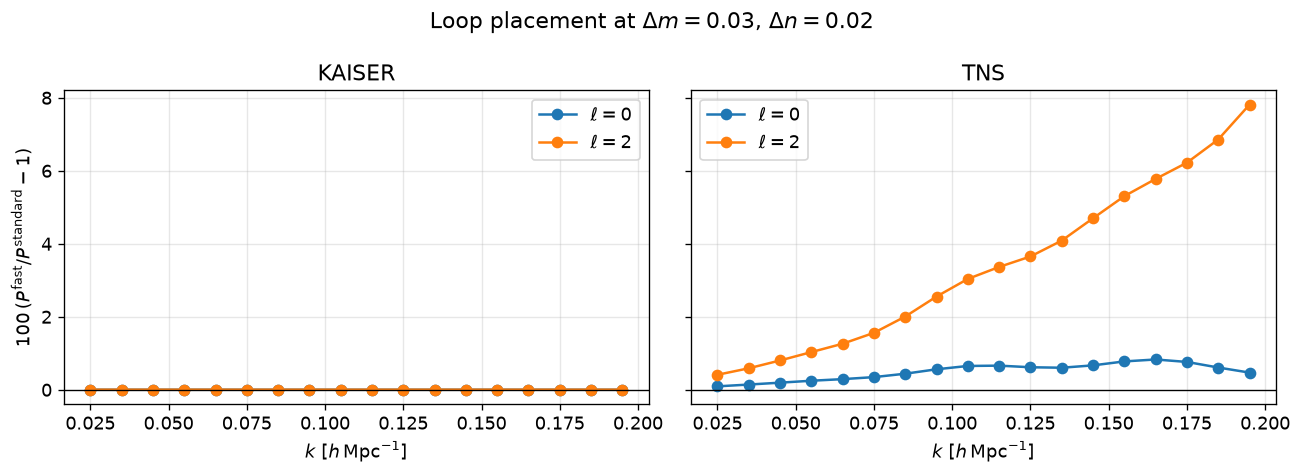

{'kaiser': '0.00% max', 'tns': '7.81% max'}


In [5]:
values = dict(truth_values)
spectra, differences = {}, {}
for kind in ('kaiser', 'tns'):
    for templ_cls, label in ((ShapeFitSpectrum2Template, 'standard'),
                             (ShapeFitFastSpectrum2Template, 'fast')):
        pipe, obs, theory = build_pipeline(kind=kind, template_cls=templ_cls, k=kf)
        spectra[(kind, label)] = get_poles(pipe, theory, values)
    differences[kind] = spectra[(kind, 'fast')] / spectra[(kind, 'standard')] - 1.

fig, axes = plt.subplots(1, 2, figsize=(11., 4.), sharey=True)
for ax, kind in zip(axes, ('kaiser', 'tns')):
    for iell, ell in enumerate(ells):
        ax.plot(kf, 100. * differences[kind][iell], 'o-',
                label=rf'$\ell={ell}$')
    ax.axhline(0., color='k', lw=0.8)
    ax.set_title(kind.upper())
    ax.set_xlabel(r'$k$ [$h\,\mathrm{Mpc}^{-1}$]')
    ax.legend()
axes[0].set_ylabel(r'$100\,(P^{\rm fast}/P^{\rm standard} - 1)$')
fig.suptitle(rf'Loop placement at $\Delta m={dm_true}$, $\Delta n={dn_true}$')
fig.tight_layout()
plt.show()
print({kind: f'{100 * np.max(np.abs(differences[kind])):.2f}% max' for kind in differences})

## 4. Cost per likelihood call

The fast template is *not* primarily a speed optimization — the standard template also
evaluates PT from scratch only when its parameters change, and with the JAX backend the
loop integrals are cheap. What changes is where the tilt enters: fast keeps the untilted
table fixed and applies an analytic factor, while standard recomputes the loop tables for
every $(\Delta m, \Delta n)$. The numbers below quantify the actual difference in cost for
a short call (typical local use).

In [6]:
import timeit

timing = []
for kind in ('kaiser', 'tns'):
    for templ_cls, label in ((ShapeFitSpectrum2Template, 'standard'),
                             (ShapeFitFastSpectrum2Template, 'fast')):
        t0 = time.time()
        pipe, obs, theory = build_pipeline(kind=kind, template_cls=templ_cls, k=kf)
        set_values(pipe, values)
        pipe()  # warm-up / trace
        build_time = time.time() - t0
        n_repeat = 20
        t0 = time.time()
        for _ in range(n_repeat):
            pipe()
        call_time = (time.time() - t0) / n_repeat
        timing.append((kind, label, build_time, 1e3 * call_time))
        print(f'{kind:6s} {label:8s}: build {build_time:6.2f} s, '
              f'{1e3 * call_time:6.3f} ms / likelihood call')

kaiser standard: build   0.10 s,  0.182 ms / likelihood call


kaiser fast    : build   0.10 s,  0.160 ms / likelihood call


tns    standard: build   0.15 s,  0.179 ms / likelihood call


tns    fast    : build   0.16 s,  0.179 ms / likelihood call


## 5. Best-fit comparison on the same data

We fit the same noiseless $z=0.5$ vector with the four combinations
(standard/fast) × (Kaiser/TNS), with identical priors and starting point, using a
deterministic Gauss–Newton fit (`scipy.optimize.least_squares` on the Cholesky-whitened
residuals). The truth used to generate the data is BRASS 2L-RPT + TNS10, so the TNS fits
are the physically relevant ones; the Kaiser fits are shown to demonstrate that at tree
level the two templates are mathematically identical.

In [7]:
from scipy.linalg import solve_triangular
from scipy.optimize import least_squares

def make_residuals(obs, pipe, names):
    data_flat = np.asarray(obs.flatdata).ravel()
    lower = np.linalg.cholesky(cov)
    def residuals(theta):
        set_values(pipe, dict(zip(names, theta)))
        pipe()
        model = np.asarray(obs.flattheory).ravel()
        return solve_triangular(lower, data_flat - model, lower=True)
    return residuals


def fit(kind, templ_cls, label, vector=None):
    pipe, obs, theory = build_pipeline(kind=kind, template_cls=templ_cls, k=kf, vector=vector)
    names = FREE_KIND[kind]
    residuals = make_residuals(obs, pipe, names)
    x0 = np.array([START[name] for name in names])
    bounds = np.array([BOUNDS[name] for name in names]).T
    t0 = time.time()
    result = least_squares(residuals, x0, bounds=bounds, x_scale='jac',
                           xtol=1e-10, ftol=1e-10, gtol=1e-10, max_nfev=500 * len(names))
    wall = time.time() - t0
    chi2 = float(np.sum(result.fun ** 2))
    chi2_truth = float(np.sum(residuals(x0) ** 2))
    print(f'{kind:6s} {label:8s}: chi2_min = {chi2:10.3f} (chi2(truth) = {chi2_truth:10.3f}), '
          f'{result.nfev:4d} evals, {wall:5.2f} s')
    return dict(kind=kind, label=label, names=names, best=result.x, chi2=chi2,
                chi2_truth=chi2_truth, nfev=result.nfev, wall=wall)

fits = {}
for kind in ('kaiser', 'tns'):
    for templ_cls, label in ((ShapeFitSpectrum2Template, 'standard'),
                             (ShapeFitFastSpectrum2Template, 'fast')):
        fits[(kind, label)] = fit(kind, templ_cls, label, vector=data)

kaiser standard: chi2_min =   1662.369 (chi2(truth) = 138143.655),   22 evals,  0.63 s


kaiser fast    : chi2_min =   1662.353 (chi2(truth) = 138143.269),   22 evals,  0.64 s


tns    standard: chi2_min =     10.396 (chi2(truth) =  57390.460),   32 evals,  2.83 s


tns    fast    : chi2_min =      4.684 (chi2(truth) =  52590.308),   24 evals,  2.28 s


In [8]:
print(f"{'param':>7s} {'truth':>9s} | " +
      ' | '.join(f'{kind[:4]}.{label[:4]:>4s}'.rjust(16) for (kind, label) in fits))
for name in ('qpar', 'qper', 'dm', 'dn', 'df', 'b1', 'b2', 'sn0', 'sigmav'):
    truth = truth_values.get(name)
    if truth is None:
        continue
    row = f'{name:>7s} {truth:9.4f} | '
    cells = []
    for key, result in fits.items():
        if name in result['names']:
            idx = result['names'].index(name)
            cells.append(f'{result["best"][idx]:16.4f}')
        else:
            cells.append(' ' * 16)
    print(row + ' | '.join(cells))

print()
for kind in ('kaiser', 'tns'):
    std, fast = fits[(kind, 'standard')], fits[(kind, 'fast')]
    dchi2 = std['chi2'] - fast['chi2']
    print(f'{kind:6s}: chi2_standard - chi2_fast = {dchi2:+.3f} '
          f'(chi2 per dof: {std["chi2"] / (data.size - len(std["names"])):.2f} / '
          f'{fast["chi2"] / (data.size - len(fast["names"])):.2f})')

  param     truth |        kais.stan |        kais.fast |         tns.stan |         tns.fast
   qpar    1.0000 |           0.9000 |           0.9000 |           1.0026 |           1.0020
   qper    1.0000 |           0.9462 |           0.9462 |           1.0015 |           1.0040
     dm    0.0300 |           0.3000 |           0.3000 |           0.3000 |           0.2476
     dn    0.0200 |          -0.2986 |          -0.2986 |          -0.2237 |          -0.1926
     df    1.0050 |           0.9500 |           0.9500 |           1.0285 |           1.0291
     b1    2.0000 |           1.8381 |           1.8381 |           1.9774 |           1.9859
     b2    0.0000 |                  |                  |           0.2625 |           0.4358
    sn0    1.0000 |           0.7467 |           0.7468 |           0.0000 |           0.0000
 sigmav    4.0000 |                  |                  |           3.5629 |           3.2205

kaiser: chi2_standard - chi2_fast = +0.016 (chi2 per dof: 5

**Reading the table.** The data were generated by BRASS (2-loop RPT + TNS10), whereas
`desilike` here uses its 1-loop TNS with Lorentzian damping, so neither template can fit the
vector exactly and $\Delta m$ is pushed to the prior edge $\Delta m = 0.3$. The best-fit
parameters therefore show the *compensation pattern* (which parameter absorbs the residual
spectral mismatch), not an unbiased recovery of the truth. The robust, model-independent
diagnostics of the loop-placement approximation are the spectral difference of section 3 and
the $\Delta\chi^2$ printed above.

The closure test below removes the theory mismatch: it generates a data vector with one of
the two prescriptions and fits it with both, so the only difference between the fits is the
loop placement.

## 5b. Closure test: data from one prescription, fitted by both

Generate a noiseless vector with the **standard** TNS template at the truth, then fit it with
the standard and the BRASS-like template. The standard fit must return the truth with
$\chi^2 \simeq 0$; the fast fit shows how much the loop-placement approximation biases the
recovered parameters on the very same data.

In [9]:
mock_pipe, mock_obs, mock_theory = build_pipeline(kind='tns', k=kf)
set_values(mock_pipe, truth_values)
mock_pipe()
closure_data = np.asarray(mock_obs.flattheory).ravel()

closure = {}
for templ_cls, label in ((ShapeFitSpectrum2Template, 'standard'),
                         (ShapeFitFastSpectrum2Template, 'fast')):
    closure[label] = fit('tns', templ_cls, label, vector=closure_data)

print(f"\n{'param':>7s} {'truth':>9s} {'standard':>10s} {'fast':>10s} {'fast - std':>12s}")
for name in FREE_KIND['tns']:
    truth = truth_values[name]
    idx = closure['standard']['names'].index(name)
    std_val = closure['standard']['best'][idx]
    fast_val = closure['fast']['best'][idx]
    print(f'{name:>7s} {truth:9.4f} {std_val:10.4f} {fast_val:10.4f} '
          f'{fast_val - std_val:+12.4f}')

tns    standard: chi2_min =      0.000 (chi2(truth) =      0.000),    1 evals,  0.09 s


tns    fast    : chi2_min =      0.499 (chi2(truth) =    608.873),    8 evals,  0.93 s

  param     truth   standard       fast   fast - std
   qpar    1.0000     1.0000     1.0001      +0.0001
   qper    1.0000     1.0000     1.0005      +0.0005
     dm    0.0300     0.0300     0.0502      +0.0202
     dn    0.0200     0.0200    -0.0070      -0.0270
     df    1.0050     1.0050     1.0039      -0.0011
     b1    2.0000     2.0000     1.9968      -0.0032
     b2    0.0000     0.0000    -0.0898      -0.0898
    sn0    1.0000     1.0000     1.1328      +0.1328
 sigmav    4.0000     4.0000     4.0569      +0.0569


The standard fit returns the truth almost exactly ($\chi^2 \lesssim 10^{-6}$ by construction);
the fast fit bends to a different point. The shifts it needs are the size of the systematic
error introduced by applying the tilt to the loop *results* instead of the loop *integrands*.

## 6. Best-fit spectra

The data vector, both best fits (standard and fast TNS), and the residuals. In $k\,P(k)$
scaling, the same convention as the main report.

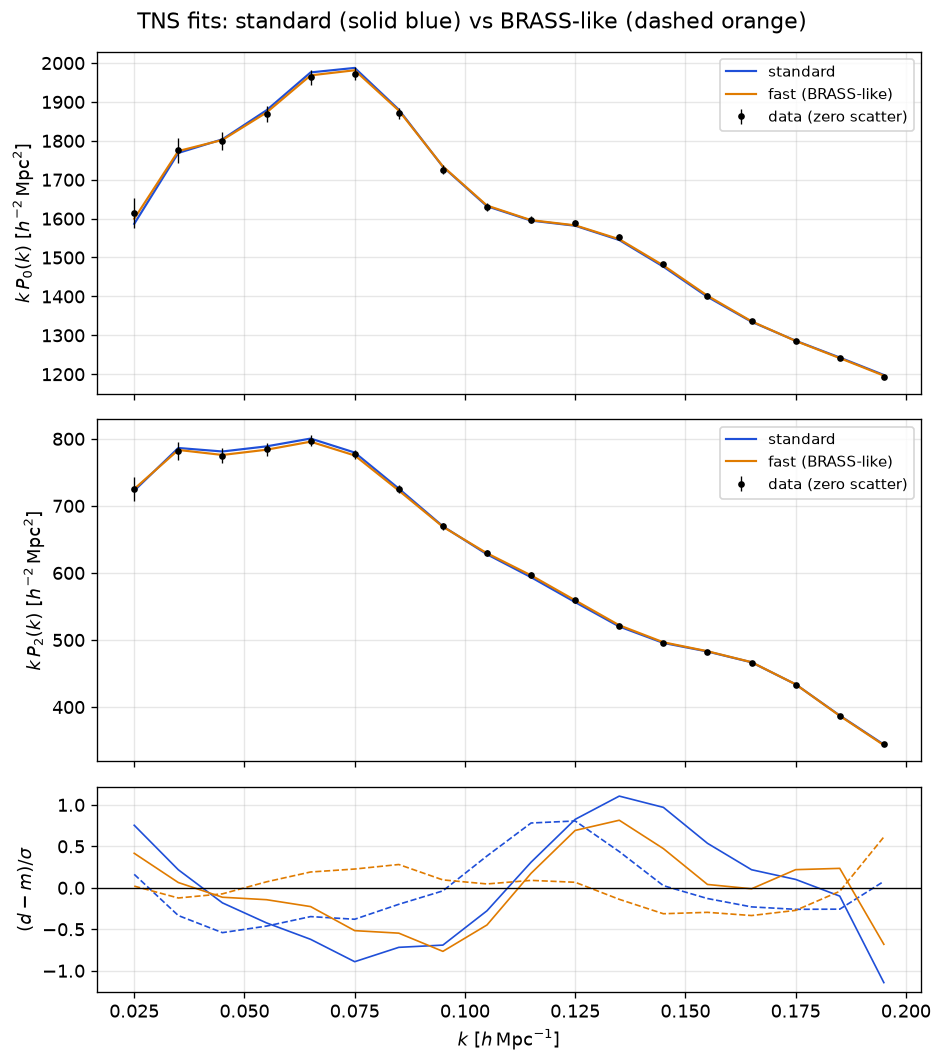

In [10]:
def model_curve(fit_result):
    kind, label = fit_result['kind'], fit_result['label']
    templ_cls = ShapeFitSpectrum2Template if label == 'standard' else ShapeFitFastSpectrum2Template
    pipe, obs, theory = build_pipeline(kind=kind, template_cls=templ_cls, k=kf)
    set_values(pipe, dict(zip(fit_result['names'], fit_result['best'])))
    pipe()
    return np.asarray(theory.poles)


fig, axes = plt.subplots(3, 1, figsize=(8., 9.), sharex=True,
                         gridspec_kw={'height_ratios': [2., 2., 1.2]})
colors = {'standard': '#1f4fd8', 'fast': '#e07b00'}
sel = {ell: slice(iell * kf.size, (iell + 1) * kf.size) for iell, ell in enumerate(ells)}
for iell, ell in enumerate(ells):
    ax = axes[iell]
    ax.errorbar(kf, kf * data[sel[ell]], kf * np.sqrt(np.diag(cov)[sel[ell]]),
                fmt='ko', ms=3., lw=0.8, label='data (zero scatter)', zorder=3)
    for label in ('standard', 'fast'):
        curve = model_curve(fits[('tns', label)])
        ax.plot(kf, kf * curve[iell], color=colors[label], lw=1.3,
                label=f'{"standard" if label == "standard" else "fast (BRASS-like)"}')
    ax.set_ylabel(rf'$k\,P_{ell}(k)$ [$h^{{-2}}\,\mathrm{{Mpc}}^2$]')
    ax.legend(fontsize=9)
ax = axes[2]
for label in ('standard', 'fast'):
    curve = model_curve(fits[('tns', label)])
    for iell, ell in enumerate(ells):
        ax.plot(kf, (data[sel[ell]] - curve[iell]) / np.sqrt(np.diag(cov)[sel[ell]]),
                color=colors[label], ls='-' if iell == 0 else '--', lw=1.)
ax.axhline(0., color='k', lw=0.8)
ax.set_xlabel(r'$k$ [$h\,\mathrm{Mpc}^{-1}$]')
ax.set_ylabel(r'$(d - m)/\sigma$')
fig.suptitle('TNS fits: standard (solid blue) vs BRASS-like (dashed orange)')
fig.tight_layout()
plt.show()

## 7. Guard: PT engines that cannot be tilted term by term

`ShapeFitFastSpectrum2Template` requires a PT calculator that provides a per-diagram table
and declares `supports_fast_shapefit = True`. The others refuse at construction time rather
than silently returning a wrong model.

In [11]:
try:
    FOLPSPTSpectrum2Poles(template=ShapeFitFastSpectrum2Template(z=z, fiducial=COSMO),
                          ells=ells, k=kf, nk=120, nfftlog=128)
except NotImplementedError as exc:
    print('NotImplementedError:', str(exc).split('\n')[0])
else:
    raise RuntimeError('FOLPS should not accept the fast template')

NotImplementedError: FOLPSPTSpectrum2Poles does not implement the per-term ShapeFit tilt hook required by ShapeFitFastSpectrum2Template: its loop table mixes the linear and loop contributions, so the tilt cannot be applied to the loop results separately. Use KaiserPTSpectrum2Poles or TNSPTSpectrum2Poles instead.


## 8. Summary and how to read it

* At $\Delta m = \Delta n = 0$ the two templates are *bitwise* identical for both PT engines (the printed max relative difference is exactly 0), confirming that the fast template only changes *where* the tilt enters.
* At the true tilt, Kaiser is also identical (tree level, one power of $P_{11}$ per term) up to interpolation; the TNS answer differs by a few per cent in the 1-loop terms, growing with $k$ and with the tilt. This is precisely the size of the BRASS approximation.
* The fast template is a fixed-table approximation: PT is evaluated once at the fiducial cosmology and the tilt is an analytic factor on top. For the standard template the loop tables are rebuilt for each $(\Delta m, \Delta n)$; the measured cost difference for a local short call is reported in the timing table.
* The best-fit section answers the practical question: given the *same* data and priors, how far do $\Delta m$, $\Delta n$ and the nuisance parameters move between the two prescriptions? Any shift there is the systematic uncertainty introduced by the BRASS loop-placement approximation, and should be compared with the statistical errors from the MCMC runs in the main report.